# Eksploracyjna analiza danych dotyczących cen produktów spożywczych w Polsce w latach 2019-2025


In [1]:
#import biblioytek
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")


In [2]:
#wczytanie pliku csv
from google.colab import files
uploaded = files.upload()

df = pd.read_csv("CENY.csv", sep=";", na_values=["-"], decimal=",")
df.head()

Saving CENY2.csv to CENY2.csv


,Produkt,2019,2020,2021,2022,2023,2024,2025
0,ryż - za 1kg,3.96,4.24,4.59,5.72,6.48,6.23,6.32
1,bułka pszenna - za 50g,0.48,0.53,0.56,0.70,0.79,NaN,NaN
2,bułka pszenna mała wagi do 60g – za 1 szt.,NaN,NaN,NaN,NaN,NaN,0.84,0.88
3,mąka pszenna (1) - za 1kg,NaN,NaN,NaN,NaN,4.08,3.87,3.76
4,chleb żytni razowy zwykły - za 1kg,6.90,NaN,NaN,NaN,NaN,NaN,NaN


W oryginalnym zbiorze danych brakujące wartości zostały oznaczone symbolem -. Podczas wczytywania pliku CSV zastosowano parametr na_values=["-"], który umożliwił automatyczne rozpoznanie tych oznaczeń jako brakujących danych (NaN).

In [3]:
print("Wymiary zbioru:", df.shape)

df.info()

display(df.head(10))

print("\nBraki danych:")
print(df.isnull().sum())

print("\nBrakujące wartości:")
print(df.isna().sum())


Wymiary zbioru: (63, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 63 entries, 0 to 62
Data columns (total 8 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Produkt  63 non-null     object 
 1   2019     47 non-null     float64
 2   2020     47 non-null     float64
 3   2021     47 non-null     float64
 4   2022     47 non-null     float64
 5   2023     48 non-null     float64
 6   2024     47 non-null     float64
 7   2025     48 non-null     float64
dtypes: float64(7), object(1)
memory usage: 4.1+ KB


,Produkt,2019,2020,2021,2022,2023,2024,2025
0,ryż - za 1kg,3.96,4.24,4.59,5.72,6.48,6.23,6.32
1,bułka pszenna - za 50g,0.48,0.53,0.56,0.70,0.79,NaN,NaN
2,bułka pszenna mała wagi do 60g – za 1 szt.,NaN,NaN,NaN,NaN,NaN,0.84,0.88
3,mąka pszenna (1) - za 1kg,NaN,NaN,NaN,NaN,4.08,3.87,3.76
4,chleb żytni razowy zwykły - za 1kg,6.90,NaN,NaN,NaN,NaN,NaN,NaN
5,chleb żytni razowy - za 1kg,NaN,8.11,8.80,10.98,12.63,13.41,13.99
6,"chleb pszenno-żytni - za 0,5kg",2.66,2.91,3.17,4.16,4.82,5.13,5.38
7,musli zbożowe z dodatkami (np. owoców) - za 350g,NaN,NaN,NaN,NaN,NaN,8.36,8.62
8,makaron jajeczny - za 400g,4.26,4.48,4.67,5.49,6.42,6.60,6.49
9,mąka pszenna - za 1kg,2.73,2.97,3.10,4.20,4.08,3.87,3.76



Braki danych:
Produkt     0
2019       16
2020       16
2021       16
2022       16
2023       15
2024       16
2025       15
dtype: int64

Brakujące wartości:
Produkt     0
2019       16
2020       16
2021       16
2022       16
2023       15
2024       16
2025       15
dtype: int64


In [4]:
braki = pd.DataFrame({
    "Liczba braków": df.isna().sum(),
    "Procent braków [%]": df.isna().mean() * 100
})

display(braki.round(2))

,Liczba braków,Procent braków [%]
Produkt,0,0.00
2019,16,25.40
2020,16,25.40
2021,16,25.40
2022,16,25.40
2023,15,23.81
2024,16,25.40
2025,15,23.81


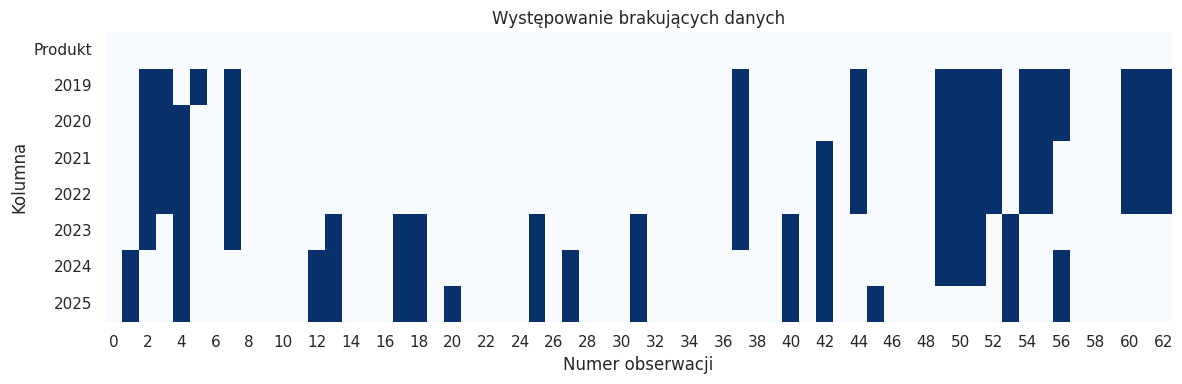

In [5]:
#wizualizacja braków

plt.figure(figsize=(12, 4))

sns.heatmap(
    df.isna().T,
    cmap="Blues",
    cbar=False,
    yticklabels=True
)

plt.title("Występowanie brakujących danych")
plt.xlabel("Numer obserwacji")
plt.ylabel("Kolumna")
plt.tight_layout()
plt.show()


Analizowany zbiór danych zawiera 63 produkty spożywcze oraz 8 kolumn. Kolumna Produkt zawiera nazwy artykułów wraz z jednostkami, natomiast pozostałe siedem kolumn przedstawia ich ceny w poszczególnych latach od 2019 do 2025.

W zbiorze występują brakujące wartości cenowe. Ich liczba wynosi od 15 do 17 w zależności od roku, co stanowi od ok 24% do 26% wszystkich produktów. Łącznie brakuje 110 spośród 441 możliwych obserwacji cenowych.

Braki mogą wynikać między innymi ze zmian zakresu monitorowanych artykułów oraz ich klasyfikacji w kolejnych latach. Z tego względu nie zdecydowano się na automatyczne uzupełnianie brakujących cen.

W dalszym etapie analizy zbiór zostanie ograniczony do wybranych podstawowych produktów spożywczych, dla których dostępne są kompletne dane w latach 2019-2025. Pozwoli to na utworzenie porównywalnego koszyka zakupowego.

In [6]:
#wyświetlenie wszystkich produktów
for produkt in df["Produkt"]:
    print(produkt)

ryż - za 1kg
bułka pszenna - za 50g
bułka pszenna mała wagi do 60g – za 1 szt.
mąka pszenna (1) - za 1kg
chleb żytni razowy zwykły - za 1kg
chleb żytni razowy - za 1kg
chleb pszenno-żytni - za 0,5kg
musli zbożowe z dodatkami (np. owoców) - za 350g
makaron jajeczny - za 400g
mąka pszenna - za 1kg
kasza jęczmienna - za 0,5kg
kasza gryczana, prażona - za 0,5kg
musli zbożowe z dodatkiem owoców - za 350g
mięso wołowe z kością (rostbef) - za 1kg
mięso wieprzowe bez kości (schab) - za 1 kg
mięso wieprzowe bez kości (łopatka) - za 1kg
kurczęta patroszone - za 1kg
szynka wieprzowa gotowana - za 1kg
baleron gotowany - za 1kg
kiełbasa sucha - za 1kg
kiełbasa wędzona - za 1kg
boczek wędzony - za 1kg
polędwica drobiowa - za 1kg
salceson - za 1kg
kiszka kaszana - za 1kg
konserwa mięsna, wieprzowa - za 300g
filety z morszczuka mrożone - za 1kg
karp świeży - za 1kg
makrela wędzona, odgłowiona - 1kg
mleko krowie spożywcze o zawartości tłuszczu 3-3,5%, sterylizowane - za 1l
jogurt owocowy - za 150g
ser 

In [7]:
#kopia danych
df_clean = df.copy()

In [8]:
#wybór produktów do koszyka - według uznania
produkty_koszyka = [
    "ryż - za 1kg",
    "mąka pszenna - za 1kg",
    "chleb pszenno-żytni - za 0,5kg",
    "kiełbasa sucha - za 1kg",
    "mięso wieprzowe bez kości (schab) - za 1 kg",
    "polędwica drobiowa - za 1kg",
    "jaja kurze świeże - za 1szt.",
    "cukier biały kryształ - za 1kg",
    "masło świeże o zawartości tłuszczu ok. 82,5% - za 200g",
    "sok jabłkowy - za 1l",
    "herbata czarna, liściasta (1) - za 100g",
    "mleko krowie spożywcze o zawartości tłuszczu 3-3,5%, sterylizowane - za 1l",
    "makaron jajeczny - za 400g"
]

In [9]:
#filtracja danych - pozostawienie tylko tych z koszuka zakupowego
df_clean = df_clean[df_clean["Produkt"].isin(produkty_koszyka)].copy()

In [10]:
#sprawdzenie danych
print("Wymiary przed filtrowaniem:", df.shape)
print("Wymiary po filtrowaniu:", df_clean.shape)

display(df_clean)

Wymiary przed filtrowaniem: (63, 8)
Wymiary po filtrowaniu: (13, 8)


,Produkt,2019,2020,2021,2022,2023,2024,2025
0,ryż - za 1kg,3.96,4.24,4.59,5.72,6.48,6.23,6.32
6,"chleb pszenno-żytni - za 0,5kg",2.66,2.91,3.17,4.16,4.82,5.13,5.38
8,makaron jajeczny - za 400g,4.26,4.48,4.67,5.49,6.42,6.60,6.49
9,mąka pszenna - za 1kg,2.73,2.97,3.10,4.20,4.08,3.87,3.76
14,mięso wieprzowe bez kości (schab) - za 1 kg,18.99,19.17,17.99,21.84,25.73,26.02,25.04
19,kiełbasa sucha - za 1kg,33.35,37.01,37.85,42.43,47.94,50.31,52.02
22,polędwica drobiowa - za 1kg,20.39,21.66,22.23,26.17,29.73,31.33,35.49
29,mleko krowie spożywcze o zawartości tłuszczu 3...,2.71,2.94,3.05,3.80,4.37,4.33,4.40
34,jaja kurze świeże - za 1szt.,0.64,0.64,0.67,0.81,0.99,0.94,1.13
38,"masło świeże o zawartości tłuszczu ok. 82,5% -...",5.91,5.53,5.75,7.87,6.90,7.78,8.99


Na potrzeby dalszej analizy ograniczono oryginalny zbiór, obejmujący 63 produkty spożywcze, do 13 wybranych artykułów reprezentujących podstawowe kategorie codziennych zakupów. W skład koszyka wchodzą: ryż, mąka pszenna, chleb pszenno-żytni, kiełbasa sucha, schab wieprzowy, polędwica drobiowa, jaja kurze, cukier, masło, sok jabłkowy, herbata czarna, mleko oraz makaron jajeczny.

Wyboru dokonano ze względu na ich zastosowanie w codziennej konsumpcji oraz zróżnicowanie kategorii produktów, a także pełne dane na przestrzeni lat.

Przyjęty koszyk ma charakter przykładowy i analityczny. Nie stanowi oficjalnego koszyka konsumpcyjnego GUS ani nie odzwierciedla pełnej struktury wydatków gospodarstw domowych.

In [12]:
#sprawdzenie danych po filtorwaniu

#braki
print("Brakujące wartości:")
print(df_clean.isna().sum())

#ilosc produktów
print("\nLiczba produktów:", df_clean.shape[0])

#duplikat
print("Duplikaty:", df_clean.duplicated().sum())

Brakujące wartości:
Produkt    0
2019       0
2020       0
2021       0
2022       0
2023       0
2024       0
2025       0
dtype: int64

Liczba produktów: 13
Duplikaty: 0


In [13]:
df_clean = df_clean.reset_index(drop=True)

In [15]:
display(df_clean.describe().round(2))

,2019,2020,2021,2022,2023,2024,2025
count,13.00,13.00,13.00,13.00,13.00,13.00,13.00
mean,8.43,8.94,9.07,10.75,12.16,12.60,12.99
std,9.72,10.60,10.70,12.06,13.75,14.47,15.25
min,0.64,0.64,0.67,0.81,0.99,0.94,1.13
25%,2.71,2.94,3.10,4.16,4.55,4.61,4.40
50%,3.96,4.24,4.59,5.49,6.42,6.23,6.32
75%,7.61,7.98,7.89,8.32,10.00,11.77,11.15
max,33.35,37.01,37.85,42.43,47.94,50.31,52.02


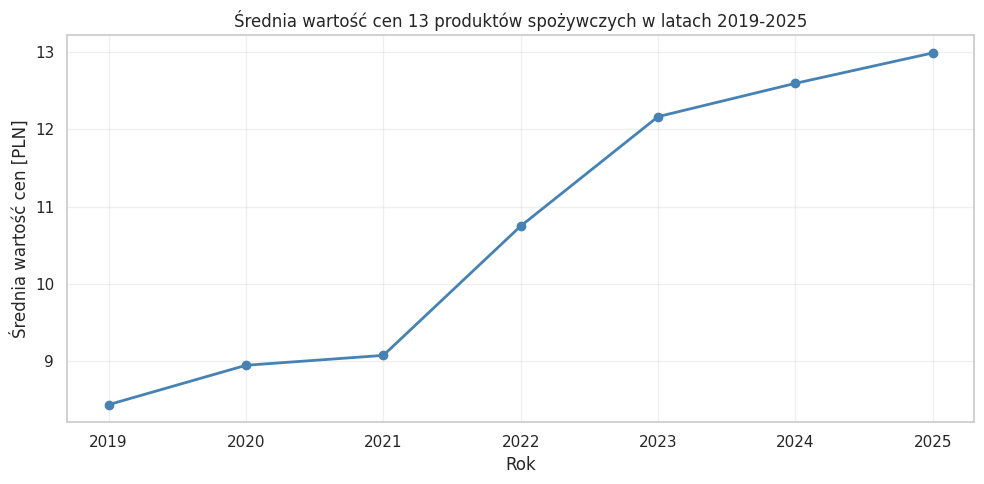

In [17]:
#obliczenie średnich cen produktów w każdym roku
srednie_ceny = df_clean.loc[:, "2019":"2025"].mean()

plt.figure(figsize=(10, 5))

plt.plot(
    srednie_ceny.index,
    srednie_ceny.values,
    marker="o",
    linewidth=2,
    color="steelblue"
)

plt.title("Średnia wartość cen 13 produktów spożywczych w latach 2019-2025")
plt.xlabel("Rok")
plt.ylabel("Średnia wartość cen [PLN]")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Analiza statystyk opisowych 13 wybranych produktów spożywczych wykazała wzrost nominalnych wartości cen w latach 2019=2025. Średnia arytmetyczna cen wzrosła z 8,43 zł do 12,99 zł, natomiast mediana z 3,96 zł do 6,32 zł.

Największe wzrosty średnich wartości zaobserwowano w latach 2022-2023. Jednocześnie odchylenie standardowe wzrosło z 9,72 zł do 15,25 zł, co wskazuje na zwiększenie zróżnicowania nominalnych cen produktów.

Należy jednak zaznaczyć, że analizowane produkty mają różne jednostki miary i wielkości dlatego przedstawione statystyki nie stanowią miary ogólnego wzrostu cen żywności ani kosztu koszyka zakupowego.

In [19]:
#procentowa zmiana cen produktów w latach 2019-2025
df_clean["zmiana_2019_2025"] = ((df_clean["2025"] - df_clean["2019"])/ df_clean["2019"]) * 100

#produkty od największego wzrostu cen
display(df_clean[["Produkt", "2019", "2025", "zmiana_2019_2025"]].sort_values("zmiana_2019_2025",ascending=False).round(2))

,Produkt,2019,2025,zmiana_2019_2025
1,"chleb pszenno-żytni - za 0,5kg",2.66,5.38,102.26
8,jaja kurze świeże - za 1szt.,0.64,1.13,76.56
6,polędwica drobiowa - za 1kg,20.39,35.49,74.06
7,mleko krowie spożywcze o zawartości tłuszczu 3...,2.71,4.40,62.36
0,ryż - za 1kg,3.96,6.32,59.60
5,kiełbasa sucha - za 1kg,33.35,52.02,55.98
2,makaron jajeczny - za 400g,4.26,6.49,52.35
9,"masło świeże o zawartości tłuszczu ok. 82,5% -...",5.91,8.99,52.12
12,"herbata czarna, liściasta (1) - za 100g",7.61,11.15,46.52
11,sok jabłkowy - za 1l,3.89,5.42,39.33


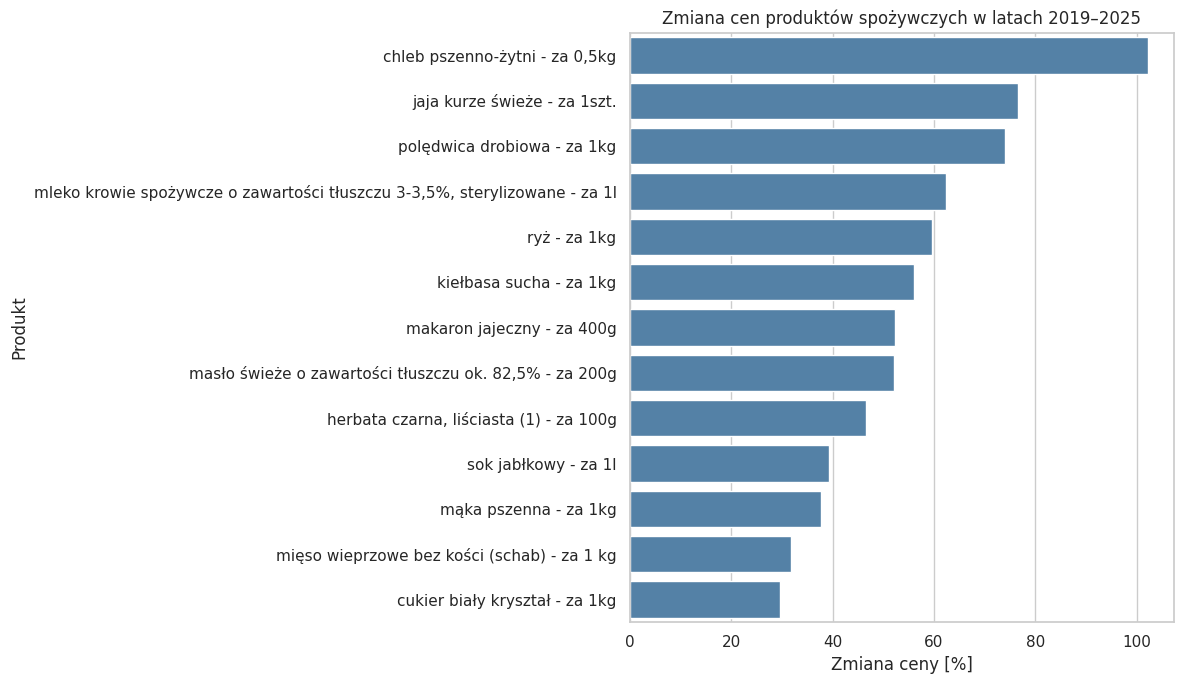

In [20]:
dane_wykres = df_clean.sort_values(
    "zmiana_2019_2025",
    ascending=False
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=dane_wykres,
    x="zmiana_2019_2025",
    y="Produkt",
    color="steelblue"
)

plt.title("Zmiana cen produktów spożywczych w latach 2019–2025")
plt.xlabel("Zmiana ceny [%]")
plt.ylabel("Produkt")
plt.tight_layout()
plt.show()

Analiza wykazała wzrost cen wszystkich 13 produktów spożywczych w latach 2019–2025, jednak skala podwyżek była zróżnicowana.

Największy wzrost ceny odnotowano w przypadku chleba pszenno-żytniego (102,26%), którego cena wzrosła ponad dwukrotnie. Znaczne podwyżki wystąpiły również w przypadku jaj kurzych (76,56%), polędwicy drobiowej (74,06%) oraz mleka (62,36%).

Najmniejsze wzrosty cen zaobserwowano dla cukru białego (29,64%), schabu wieprzowego (31,86%) oraz mąki pszennej (37,73%).

Wyniki wskazują, że wzrost cen artykułów spożywczych nie był jednakowy dla wszystkich produktów. Zjawisko to może mieć znaczenie dla struktury wydatków gospodarstw domowych, szczególnie w przypadku artykułów kupowanych regularnie.

In [24]:
lata = [str(rok) for rok in range(2019, 2026)]

#procentowe zmiany cen rok do roku
zmiany_roczne = df_clean[lata].pct_change(axis=1,fill_method=None) * 100

#dodanie nazw produktów
zmiany_roczne.insert(0, "Produkt", df_clean["Produkt"])

#uunięcie 2019, bo nie mamy danych z 2018 roku
zmiany_roczne = zmiany_roczne.drop(columns=["2019"])

display(zmiany_roczne.round(2))

,Produkt,2020,2021,2022,2023,2024,2025
0,ryż - za 1kg,7.07,8.25,24.62,13.29,-3.86,1.44
1,"chleb pszenno-żytni - za 0,5kg",9.40,8.93,31.23,15.87,6.43,4.87
2,makaron jajeczny - za 400g,5.16,4.24,17.56,16.94,2.80,-1.67
3,mąka pszenna - za 1kg,8.79,4.38,35.48,-2.86,-5.15,-2.84
4,mięso wieprzowe bez kości (schab) - za 1 kg,0.95,-6.16,21.40,17.81,1.13,-3.77
5,kiełbasa sucha - za 1kg,10.97,2.27,12.10,12.99,4.94,3.40
6,polędwica drobiowa - za 1kg,6.23,2.63,17.72,13.60,5.38,13.28
7,mleko krowie spożywcze o zawartości tłuszczu 3...,8.49,3.74,24.59,15.00,-0.92,1.62
8,jaja kurze świeże - za 1szt.,0.00,4.69,20.90,22.22,-5.05,20.21
9,"masło świeże o zawartości tłuszczu ok. 82,5% -...",-6.43,3.98,36.87,-12.33,12.75,15.55


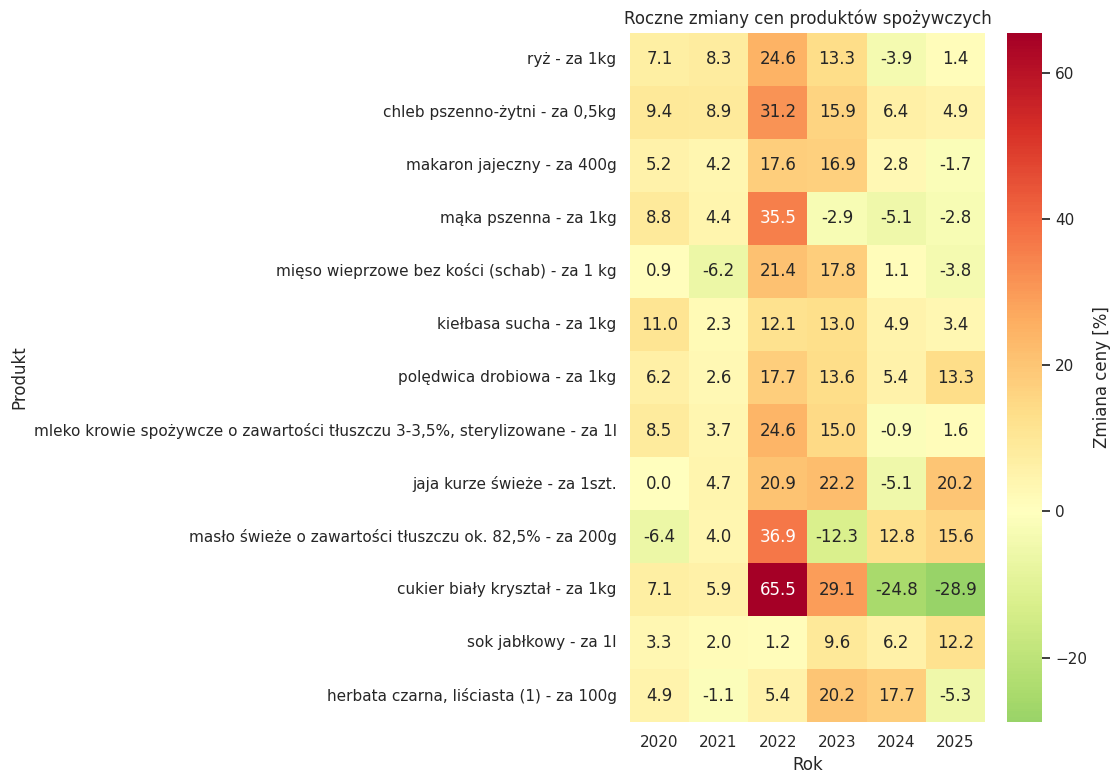

In [25]:
plt.figure(figsize=(11, 8))

sns.heatmap(
    zmiany_roczne.set_index("Produkt"),
    annot=True,
    fmt=".1f",
    cmap="RdYlGn_r",
    center=0,
    cbar_kws={"label": "Zmiana ceny [%]"}
)

plt.title("Roczne zmiany cen produktów spożywczych")
plt.xlabel("Rok")
plt.ylabel("Produkt")
plt.tight_layout()
plt.show()

Największa fala podwyżek wystąpiła w 2022 roku, kiedy wzrosły ceny wszystkich analizowanych artykułów. Największe wzrosty odnotowano dla cukru (65,51%), masła (36,87%), mąki pszennej (35,48%) oraz chleba pszenno-żytniego (31,23%).

W 2023 roku wzrost cen większości produktów był kontynuowany, jednak pojawiły się również spadki, m.in. w przypadku masła i mąki. W latach 2024-2025 dynamika cen była bardziej zróżnicowana, część artykułów nadal drożała, podczas gdy inne wykazywały spadki.

Szczególnie duże wahania zaobserwowano w przypadku cukru, którego cena silnie wzrosła w latach 2022-2023, a następnie znacząco spadła w latach 2024-2025.

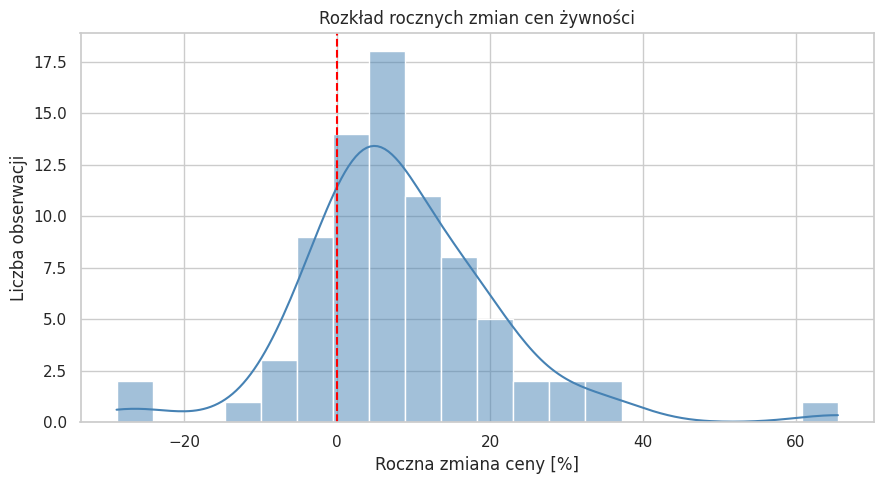

In [26]:
#zamiana tabeli zmian na jedną serię wartości
wszystkie_zmiany = zmiany_roczne.drop(
    columns=["Produkt"]
).to_numpy().flatten()

plt.figure(figsize=(9, 5))

sns.histplot(
    wszystkie_zmiany,
    bins=20,
    kde=True,
    color="steelblue"
)

plt.axvline(0, color="red", linestyle="--")

plt.title("Rozkład rocznych zmian cen żywności")
plt.xlabel("Roczna zmiana ceny [%]")
plt.ylabel("Liczba obserwacji")
plt.tight_layout()
plt.show()

Większość obserwacji przyjmuje wartości dodatnie, a największa koncentracja zmian występuje w przedziale około 0-15%, co wskazuje na przewagę rocznych wzrostów cen nad spadkami.

Rozkład wykazuje asymetrię prawostronną.

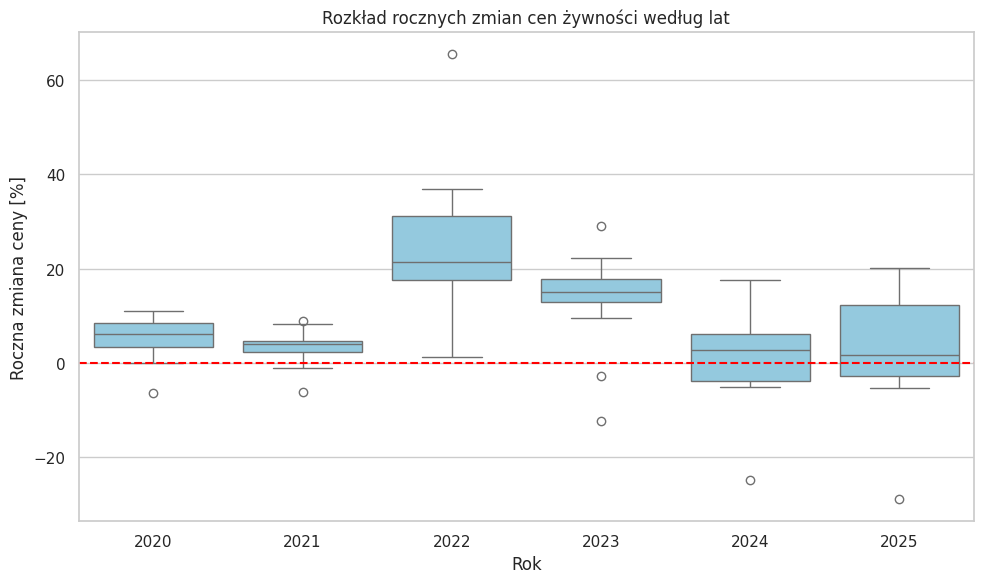

In [29]:
zmiany_long = zmiany_roczne.melt(
    id_vars="Produkt",
    var_name="Rok",
    value_name="Zmiana [%]"
)

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=zmiany_long,
    x="Rok",
    y="Zmiana [%]",
    color="skyblue"
)

plt.axhline(
    0,
    color="red",
    linestyle="--"
)

plt.title("Rozkład rocznych zmian cen żywności według lat")
plt.xlabel("Rok")
plt.ylabel("Roczna zmiana ceny [%]")
plt.tight_layout()
plt.show()


Wykres pudełkowy również wskazuje, że największe wzrosty cen analizowanych produktów spożywczych wystąpiły w 2022 roku, kiedy wszystkie 13 artykułów podrożało, a mediana rocznych zmian przekroczyła 20%. W 2023 roku większość produktów nadal drożała, jednak pojawiły się również spadki cen niektórych artykułów.

W latach 2024-2025 zaobserwowano większe zróżnicowanie kierunku zmian, obejmujące zarówno podwyżki, jak i obniżki cen. Widoczne wartości odstające, szczególnie dotyczące cukru, wskazują na występowanie nietypowo dużych zmian cen pojedynczych produktów.

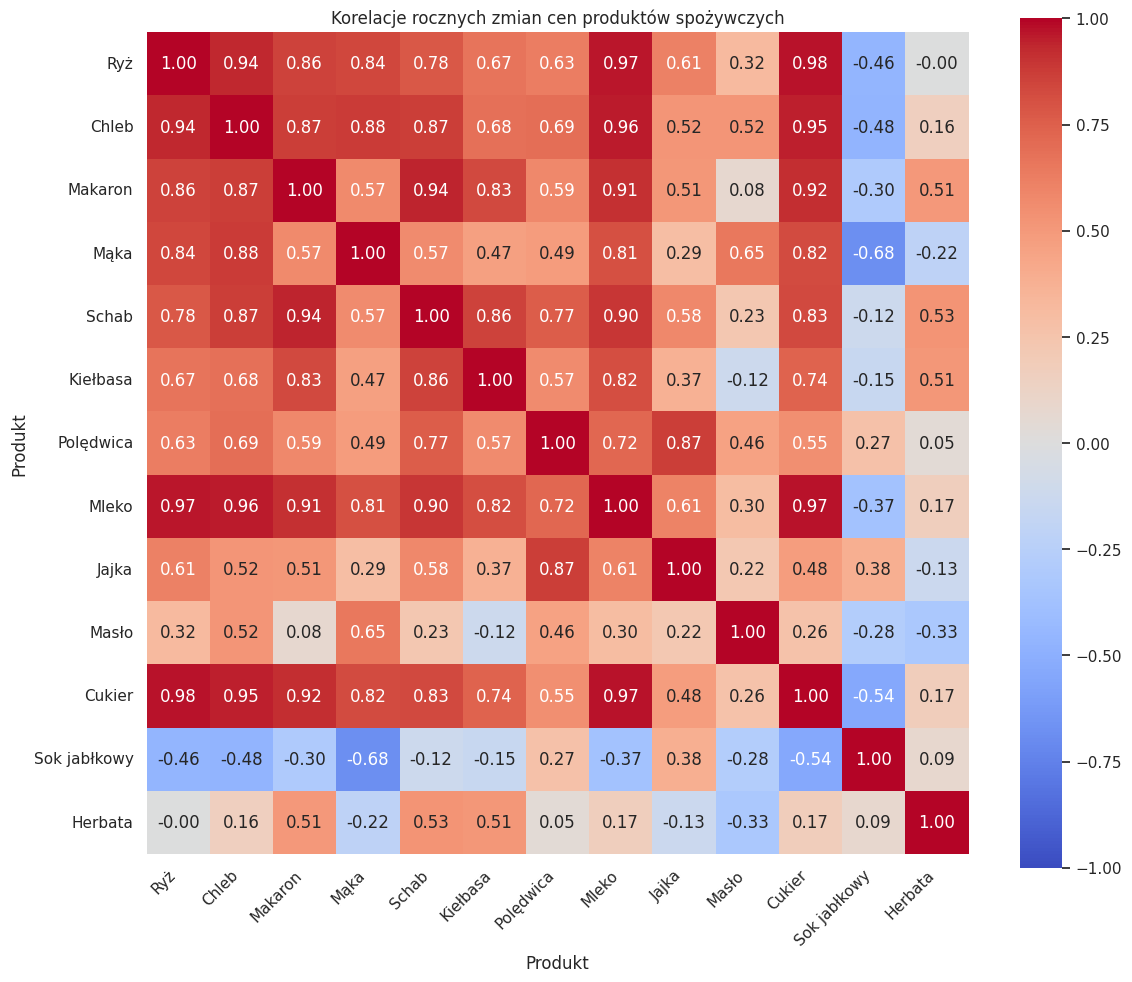

In [32]:
dane_korelacje = zmiany_roczne.set_index("Produkt").T

krotkie_nazwy = [
    "Ryż", "Chleb", "Makaron", "Mąka",
    "Schab", "Kiełbasa", "Polędwica",
    "Mleko", "Jajka", "Masło", "Cukier",
    "Sok jabłkowy", "Herbata"
]

#zmiana nazw kolumn
dane_korelacje.columns = krotkie_nazwy

#obliczenie macierzy korelacji
korelacje = dane_korelacje.corr()

#wykres macierzy korelacji
plt.figure(figsize=(12, 10))

sns.heatmap(
    korelacje,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Korelacje rocznych zmian cen produktów spożywczych")
plt.xlabel("Produkt")
plt.ylabel("Produkt")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Macierz korelacji wskazuje na przewagę dodatnich zależności między rocznymi zmianami cen analizowanych produktów spożywczych. Szczególnie silne korelacje zaobserwowano między chlebem pszenno-żytnim a ryżem (r = 0,94) oraz chlebem a cukrem (r = 0,95), co sugeruje podobną dynamikę zmian ich cen w badanym okresie.

Nie wszystkie produkty wykazywały jednak zbliżone tendencje, czego przykładem jest ujemna korelacja między ryżem a sokiem jabłkowym (r = −0,46)..

In [33]:
lata = [str(rok) for rok in range(2019, 2026)]

#[obliczenie indeksów cen (2019 = 100)
indeksy_cen = df_clean[lata].div(
    df_clean["2019"], axis=0
) * 100

indeksy_cen.insert(0, "Produkt", df_clean["Produkt"])

display(indeksy_cen.round(2))


,Produkt,2019,2020,2021,2022,2023,2024,2025
0,ryż - za 1kg,100.0,107.07,115.91,144.44,163.64,157.32,159.60
1,"chleb pszenno-żytni - za 0,5kg",100.0,109.40,119.17,156.39,181.20,192.86,202.26
2,makaron jajeczny - za 400g,100.0,105.16,109.62,128.87,150.70,154.93,152.35
3,mąka pszenna - za 1kg,100.0,108.79,113.55,153.85,149.45,141.76,137.73
4,mięso wieprzowe bez kości (schab) - za 1 kg,100.0,100.95,94.73,115.01,135.49,137.02,131.86
5,kiełbasa sucha - za 1kg,100.0,110.97,113.49,127.23,143.75,150.85,155.98
6,polędwica drobiowa - za 1kg,100.0,106.23,109.02,128.35,145.81,153.65,174.06
7,mleko krowie spożywcze o zawartości tłuszczu 3...,100.0,108.49,112.55,140.22,161.25,159.78,162.36
8,jaja kurze świeże - za 1szt.,100.0,100.00,104.69,126.56,154.69,146.87,176.56
9,"masło świeże o zawartości tłuszczu ok. 82,5% -...",100.0,93.57,97.29,133.16,116.75,131.64,152.12


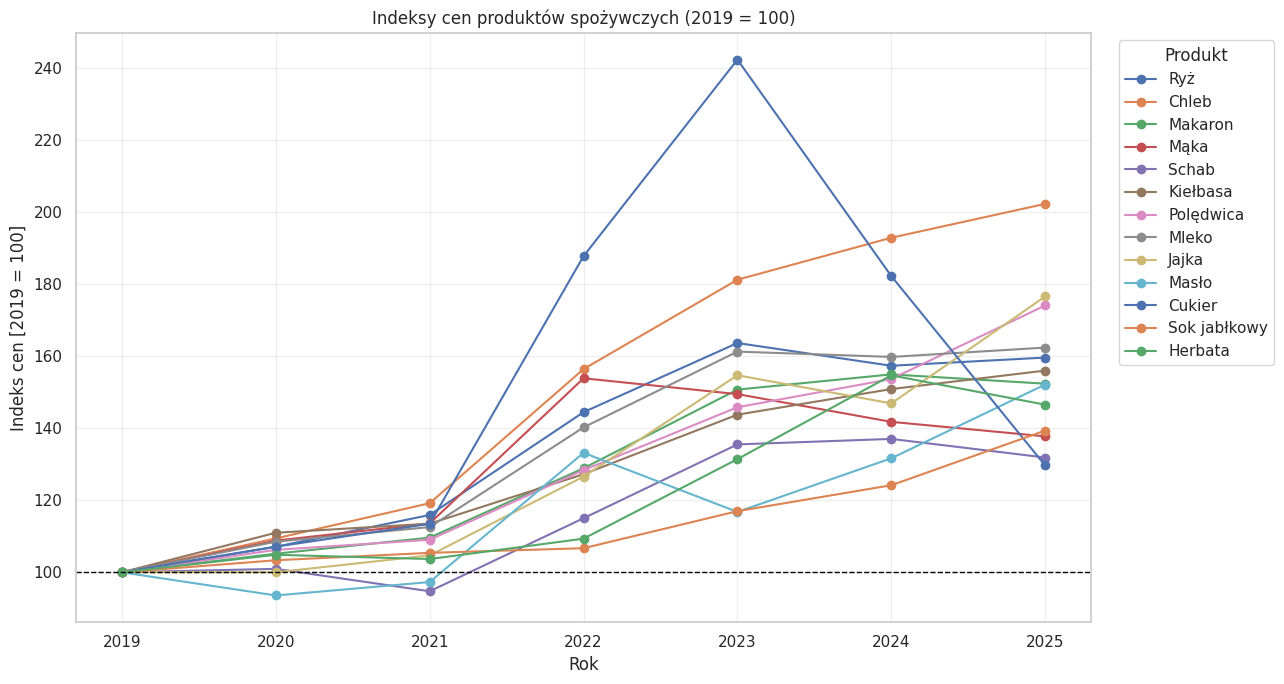

In [34]:
indeksy_wykres = indeksy_cen.set_index("Produkt").T

indeksy_wykres.columns = [
    "Ryż", "Chleb", "Makaron", "Mąka",
    "Schab", "Kiełbasa", "Polędwica",
    "Mleko", "Jajka", "Masło", "Cukier",
    "Sok jabłkowy", "Herbata"
]

plt.figure(figsize=(13, 7))

for produkt in indeksy_wykres.columns:
    plt.plot(
        indeksy_wykres.index,
        indeksy_wykres[produkt],
        marker="o",
        label=produkt
    )

plt.axhline(
    100,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.title("Indeksy cen produktów spożywczych (2019 = 100)")
plt.xlabel("Rok")
plt.ylabel("Indeks cen [2019 = 100]")
plt.legend(
    title="Produkt",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Wykres indeksów cen przedstawia zmiany cen 13 produktów spożywczych w latach 2019-2025, przyjmując rok 2019 jako bazowy (2019 = 100). Wszystkie analizowane produkty osiągnęły w 2025 roku indeks wyższy niż 100, co oznacza wzrost ich cen względem roku bazowego.

Największy wzrost odnotowano dla chleba pszenno-żytniego, którego indeks w 2025 roku wyniósł 202,26, co odpowiada wzrostowi ceny o 102,26%. Najmniejszy wzrost wystąpił dla cukru, którego indeks wyniósł 129,64, mimo że w latach 2022-2023 jego cena przejściowo wzrosła znacznie bardziej.

Wyniki wskazują na zróżnicowaną dynamikę wzrostu cen poszczególnych artykułów, a zastosowanie indeksów umożliwia ich porównanie niezależnie od jednostki miary i początkowego poziomu ceny.